In [21]:

# Import required libraries for data handling, visualization, and machine learning.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [22]:

# Load the California Housing dataset into a pandas DataFrame.

df = pd.read_csv("/content/housing.csv")

In [23]:

# Display the first few rows of the dataset.

df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [24]:

# Display dataset information such as data types and missing values.

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [25]:

# Generate statistical summary of numerical columns.

df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [26]:

# Check for missing values in each column.

df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


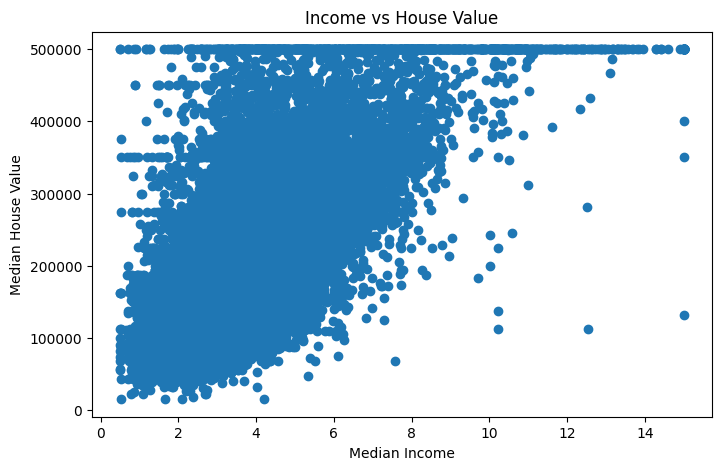

In [27]:

# Visualize the relationship between median income and house value.

plt.figure(figsize=(8,5))

plt.scatter(df["median_income"],
            df["median_house_value"])

plt.xlabel("Median Income")

plt.ylabel("Median House Value")

plt.title("Income vs House Value")

plt.show()

In [28]:

# Separate the input features (X) from the target variable (y).

X = df.drop("median_house_value", axis=1)

y = df["median_house_value"]

In [29]:

# Split the dataset into training and testing sets.

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [30]:

# Identify numerical columns.

numeric_features = X.select_dtypes(include=["int64","float64"]).columns

In [31]:

# Identify categorical columns

categorical_features = X.select_dtypes(include=["object"]).columns

In [32]:

# Replace missing numerical values with the median.

numeric_transformer = SimpleImputer(strategy="median")

In [33]:

# Fill missing categorical values and convert categories into numerical format.

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

In [34]:

# Apply preprocessing steps to numerical and categorical columns.

preprocessor = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

In [35]:

# Create a pipeline that preprocesses the data and trains a Linear Regression model.

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

In [36]:
# Train the Linear Regression model using the training data.
model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  SimpleImputer(strategy='median'),
                                                  Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income'],
      dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('encoder',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['ocean_proximity'], dtype='object'))])),
                ('regressor', LinearRegression())])

In [37]:
# Predict house prices using the test dataset.
y_pred = model.predict(X_test)

In [38]:
# Calculate model evaluation metrics.
mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

mae = mean_absolute_error(y_test, y_pred)

print("MSE :", mse)
print("RMSE :", rmse)
print("MAE :", mae)

MSE : 4908290571.346422
RMSE : 70059.19333925008
MAE : 50670.48923565593


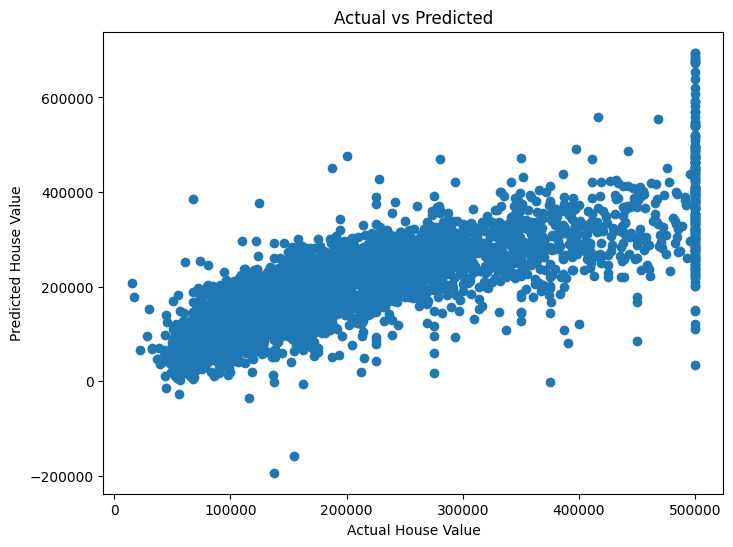

In [39]:

# Compare actual house prices with predicted values.

plt.figure(figsize=(8,6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual House Value")

plt.ylabel("Predicted House Value")

plt.title("Actual vs Predicted")

plt.show()

In [40]:

# Predict the house value for a sample from the test dataset.

sample = X_test.iloc[[0]]

prediction = model.predict(sample)

print("Predicted Value:", prediction[0])

print("Actual Value:", y_test.iloc[0])

Predicted Value: 54261.02768977778
Actual Value: 47700.0
